# Notebook 05: Interference From Indivisibility

**Goal:** Build a double-slit model as a genuine stochastic process, show that on this model
interference and indivisibility appear together, and see exactly how far that link goes.

By the end of this notebook you will be able to:
- Build the double slit as a unistochastic process on transverse modes
- Test Barandes' divisibility condition on that same model, without matrix inversion
- Reproduce Barandes's eq. 43 on this model: the fringe pattern equals the (matched) divisibility defect, entry for entry
- Tune the coherence and watch interference and indivisibility vanish together on this model
- Tell *existential* divisibility (some valid middle step exists) from *matched* divisibility
  (the eq. 42 middle step abs(U2)^2 composes), and see a fine-tuned completion where partial fringes (c ≤ 1/2)
  and existential divisibility coexist

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Working copy of `05_interference.ipynb`. Companion to the annotated copies of
> notebooks 01–04.
>
> ### 🔧 How this notebook is built
>
> The double slit here is a genuine stochastic process, and every claim is computed on
> it: the divisibility test runs on the slit model itself, and the fringe pattern is
> compared entry for entry with the divisibility defect. Three design choices make that
> possible:
>
> | choice | why |
> |---|---|
> | unitary DFT (Fraunhofer) propagator — complex, orthonormal | Born probabilities normalise on their own; `np.sinc` slit amplitudes are real and **not orthogonal**, so their probabilities do not sum to 1 (section 1) |
> | divisibility tested on **this** model, by linear program | the test and the fringes share every variable |
> | fringes compared with a column of the divisibility defect matrix | they are **equal**, to 0.00e+00, not merely similar |
>
> The linear program is needed because for a *balanced* two-slit model the inverse-based
> test of notebooks 02–03 is provably unavailable. That proof is in section 3, and it is
> why `isp` has an inverse-free divisibility test.
>
> ### 🗓 Annotations
>
> The marked cells add orientation, derivations, reading guides and source quotations.
> They are markdown cells. Every stored output is from the notebook's own run.
---


<!-- expansion:05:before-you-start -->
### 🧭 Before you start

**Purpose.** Notebooks 01–04 built the vocabulary: transition matrices, the divisibility condition, and unistochastic processes. This notebook spends it on the double slit and asks: *is the interference pattern something quantum mechanics adds on top of probability, or is it exactly the failure of the process's own two-step composition?* The answer here is computed, not argued — the fringes and the (matched) divisibility defect come out as the same array of numbers, which reproduces Barandes' Eq. (43) on this model. Section 7 then shows why "matched" matters: on one fine-tuned completion, Barandes' existential divisibility survives partial fringes ($c \le 1/2$), though not full coherence.

**Prerequisites.**

* Notebook 01: column-stochastic transition matrices and $\mathbf p(t) = \Gamma(t \leftarrow t_0)\,\mathbf p(t_0)$.
* Notebooks 02–03: the divisibility condition $\Gamma(t_2,t_0) = \Gamma(t_2,t_1)\,\Gamma(t_1,t_0)$ and the inverse-based test. Section 3 explains why that test cannot run on this model.
* Notebook 04: unistochastic matrices, $\Gamma_{ij} = \lvert U_{ij}\rvert^2$.
* Comfort with complex numbers ($\lvert z\rvert^2 = z\bar z$) and matrix multiplication. The glossary covers the rest.

**Time.** ~15 minutes to run and skim; 60–90 minutes to work through the derivations and experiments. The linear-program cells (sections 3, 5, 6) are the slowest; section 5 solves twenty-one LPs.

**How to run.** **Kernel → Restart & Run All**, or step with **Shift+Enter**. The first code cell puts the parent folder on `sys.path`, so `isp` is imported from `isp/`, one folder up from `notebooks/`. If imports fail, the notebook was opened from a different working directory.

**Headline numbers to watch for:** `0.00e+00` (fringes equal the defect column), `divisible only at c = [0.]`, and `0.603553390593` repeated across five seeds.


<!-- expansion:05:glossary -->
### 📘 Glossary

* **Transverse mode.** One of $n = 24$ discrete positions across the beam. The same labels serve as source modes ($t_0$), slit-plane positions ($t_1$) and screen pixels ($t_2$): the configuration space.
* **Amplitude / Born rule.** A complex number per transition; probability $= \lvert\text{amplitude}\rvert^2$.
* **Unitary $U$.** $U^\dagger U = I$; columns are orthonormal, so squared amplitudes sum to 1.
* **DFT / Fraunhofer propagator.** $U_2[k,m] = e^{2\pi i km/n}/\sqrt n$. Far-field diffraction is a Fourier transform, so the unitary DFT is the discrete slit-to-screen propagator.
* **Transition matrix $\Gamma(t \leftarrow t')$.** Entry $[i,j]$ = probability of $i$ at $t$ given $j$ at $t'$; columns sum to 1. Code names: `gamma_10`, `gamma_21`, `gamma_20_*`.
* **Unistochastic.** $\Gamma_{ij} = \lvert U_{ij}\rvert^2$ for some unitary $U$.
* **Divisible / indivisible.** Divisible at $t_1$ if some genuine stochastic $\Gamma(t_2,t_1)$ satisfies $\Gamma(t_2,t_0) = \Gamma(t_2,t_1)\Gamma(t_1,t_0)$ — you may stop at $t_1$, note the configuration, and restart. Indivisible if none exists.
* **Coherent vs decohered.** Coherent: amplitudes add, then square ($\lvert U_2U_1\rvert^2$). Decohered: square each path, then add probabilities ($\lvert U_2\rvert^2\lvert U_1\rvert^2$). A **which-path measurement** at the slits produces the decohered case.
* **Cross term / interference term.** The extra $\mathrm{Re}(A\bar B)$ from squaring a sum instead of summing squares. Positive or negative; sums to zero over the screen.
* **Fringe visibility.** $V = (p_{\max} - p_{\min})/(p_{\max} + p_{\min})$: 1 for fringes with true zeros, 0 for a flat pattern.
* **Divisibility defect matrix $D$.** $\Gamma(t_2,t_0) - \Gamma(t_2,t_1)\Gamma(t_1,t_0)$ with the *specific* middle matrix $\lvert U_2\rvert^2$.
* **Existential vs matched divisibility.** *Existential*: **some** stochastic middle matrix exists (Barandes' eq. 6; the LP tests it). *Matched*: the process's **own** middle matrix $\lvert U_2\rvert^2$ composes, i.e. $D = 0$. Interference always breaks matched divisibility; section 7 shows a fine-tuned completion where, for $c \le 1/2$ only, it does not break existential divisibility. The labels "existential" and "matched" are ours.
* **LP defect.** A different number: the *smallest* $L_1$ residual $\lVert M\,\Gamma(t_1,t_0) - \Gamma(t_2,t_0)\rVert_1$ over **all** stochastic $M$. Zero exactly when divisible. ($L_1$ norm = sum of absolute values.)
* **Linear program (LP).** Unknowns enter only linearly, under linear equalities and inequalities. A **feasibility LP** only asks whether any point satisfies the constraints. Solved here by SciPy `linprog` (HiGHS).
* **Witness.** The intermediate $M$ the LP returns when the process is divisible.
* **Rank / singular / left null space.** A singular matrix has rank below $n$ and no inverse; its left null space is the set of $v$ with $v^{\mathsf T}\Gamma = 0$.
* **Cauchy–Schwarz.** $\lvert\langle a,b\rangle\rvert \le \lVert a\rVert\,\lVert b\rVert$, equality only when $a \parallel b$.
* **Orthonormal completion / seed.** Only one column of $U_1$ is physical; the other 23 are a random orthonormal fill (QR of a seeded random matrix).
* **Dephasing / coherence $c$.** Shrinking the off-diagonal (phase) entries of the density matrix $\rho_{mn} = \psi_m\bar\psi_n$; $c \in [0,1]$ is the surviving fraction.
* **Division event.** Barandes' term for a time from which the process can genuinely be restarted — the stochastic counterpart of a measurement or recording interaction. Subject of notebook 06.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.divisibility import check_divisibility, check_divisibility_lp, divisibility_defect
from isp.stochastic import StochasticProcess
from isp.double_slit import (
    double_slit_matrices,
    far_field_propagator,
    fringe_visibility,
    make_double_slit_process,
    screen_distribution,
    slit_preparation,
)

## 1. The Double Slit as a Stochastic Process

Three times, one particle, n transverse modes:

    t0  source  --U1-->  t1  slit plane  --U2-->  t2  screen

U1 sends the source into the balanced superposition of the two slits.
U2 is the unitary DFT, which is Fraunhofer (far-field) propagation. Because U2 is
unitary its columns are orthonormal, so the two slit amplitude vectors are orthogonal: the
cross term sums to zero over the screen and Born-rule probabilities normalise on their own.

The transition matrices are unistochastic, G[i,j] = |U[i,j]|^2:

| matrix | meaning |
|---|---|
| G(t1,t0) = abs(U1)^2 | source to slits |
| G(t2,t1) = abs(U2)^2 | slits to screen |
| G(t2,t0) = abs(U2 U1)^2 | source to screen, coherent |

The decohered alternative, a which-path measurement at the slits, replaces the last one
with the product G(t2,t1) G(t1,t0). Whether those two agree is whether abs(U2)^2 works as
the slit-to-screen step. Divisibility asks the broader question of whether *any* valid
slit-to-screen matrix does (section 3).

<!-- expansion:05:papers-divisibility-def -->
### 📚 From the papers: the condition this notebook tests

* **Divisibility.** $\Gamma(t\leftarrow t_0)$ "will generically be indivisible", meaning that for $t > t' > t_0$ "there will not generally exist a genuinely stochastic matrix $\tilde\Gamma(t \leftarrow t')$ satisfying the composition law or divisibility condition" $\Gamma(t\leftarrow t_0) = \tilde\Gamma(t\leftarrow t')\,\Gamma(t'\leftarrow t_0)$. — *Barandes, "The Stochastic-Quantum Correspondence", Section 2, Eq. (6), p. 4.* Note the hedges "generically" and "not generally". The question is whether **any** stochastic $\tilde\Gamma$ exists — exactly what section 3's linear program asks.
* **Origin of the term.** The same passage credits "divisible" to Wolf and Cirac (2008), for quantum channels. Their *Dividing Quantum Channels* (abstract, Fig. 1) asks whether a channel factors as $T = T_1T_2$ with any non-trivial factors (Fig. 1: "any non-trivial product decomposition"); Barandes fixes the earlier step, the right-hand factor, to the process's own $\Gamma(t'\leftarrow t_0)$. This notebook uses Barandes' version.
* **Unistochastic.** "A square matrix whose individual entries are the modulus-squares of the corresponding entries of a unitary matrix." Every unistochastic matrix is also doubly stochastic. — *Same paper, §3.4, Eqs. (30)–(32).*
* **Division events.** An indivisible process has "only first-order transition probabilities connecting target times $t$ with conditioning times $t_0$", and "allowed conditioning times $t_0$ are called division events". — *Barandes, "Quantum Systems as Indivisible Stochastic Processes", Section 2.2, Eq. (18).* Here the source time $t_0$ is a division event; the slit time $t_1$ is not, unless something records the slit — section 5's coherence $c$ is a dial for that.


### 📖 In depth: why the propagator has to be unitary

A natural first attempt builds slit-to-screen amplitudes with `np.sinc`:

```python
amp = np.sinc(np.abs(screen_positions - slit_pos) / wavelength)
amp = amp / np.linalg.norm(amp)
```

Each amplitude vector is individually normalised, which looks sufficient and is not.
Superposing two of them gives

$$\left\lVert \frac{A+B}{\sqrt2} \right\rVert^2 = \frac{\lVert A\rVert^2 + \lVert B\rVert^2}{2} + \mathrm{Re}\,\langle A, B\rangle = 1 + \mathrm{Re}\,\langle A, B\rangle$$

so the Born probabilities sum to 1 **only if the two slit amplitudes are orthogonal**.
Two shifted sincs are not. A renormalisation such as `p_quantum /= p_quantum.sum()` would
silently absorb the discrepancy — here about 20% of the probability is missing, which is no
rounding tidy-up. Renormalising would also destroy the property one most wants from an interference term: that it
*redistributes* probability rather than creating or destroying it.

What is needed is not a better fudge but the right propagator. Free propagation to the far
field is a Fourier transform, and the discrete version of that is the unitary DFT

$$U_2[k,m] = \frac{1}{\sqrt{n}}\,e^{2\pi i k m / n}$$

whose columns are orthonormal *because* it is unitary. The slit amplitudes are then
genuinely complex, the relative phase advances linearly with screen position exactly as
in Fraunhofer diffraction, and normalisation takes care of itself. The next cell shows
the sinc model failing and the DFT passing, side by side.

In [2]:
# 🔍 Reading the code: the original sinc model, and exactly where it broke.

N_SCREEN = 21
screen_positions = np.linspace(-1, 1, N_SCREEN)

def slit_to_screen_amplitude(slit_pos, positions, wavelength=0.3):
    amp = np.sinc(np.abs(positions - slit_pos) / wavelength)
    return amp / np.linalg.norm(amp)

old_A = slit_to_screen_amplitude(-0.2, screen_positions)
old_B = slit_to_screen_amplitude(+0.2, screen_positions)

old_p_cl = 0.5 * old_A**2 + 0.5 * old_B**2
old_p_qm = ((old_A + old_B) / np.sqrt(2))**2

print('ORIGINAL sinc model')
print(f'  each amplitude normalised:  ||A|| = {np.linalg.norm(old_A):.6f}, '
      f'||B|| = {np.linalg.norm(old_B):.6f}')
print(f'  but they are NOT orthogonal:  <A,B> = {old_A @ old_B:+.6f}')
print(f'  so ||(A+B)/sqrt(2)||^2 = 1 + <A,B> = {1 + old_A @ old_B:.6f}, not 1')
print(f'  raw totals:  classical {old_p_cl.sum():.6f}   quantum {old_p_qm.sum():.6f}')
print(f'  interference term sums to {(old_p_qm - old_p_cl).sum():+.6f}  <- should be 0')
print(f'  the hidden `p /= p.sum()` was a {100 * abs(1 - old_p_qm.sum()):.1f}% correction')
print()

new_U2 = far_field_propagator(24)
new_A, new_B = new_U2[:, 10], new_U2[:, 13]
new_p_cl = 0.5 * np.abs(new_A)**2 + 0.5 * np.abs(new_B)**2
new_p_qm = np.abs((new_A + new_B) / np.sqrt(2))**2

print('DFT model')
print(f'  amplitudes are complex:  A[1] = {new_A[1]:+.4f}')
print(f'  and orthogonal:  <A,B> = {abs(new_A.conj() @ new_B):.2e}')
print(f'  raw totals:  classical {new_p_cl.sum():.15f}   quantum {new_p_qm.sum():.15f}')
print(f'  interference term sums to {(new_p_qm - new_p_cl).sum():+.2e}  <- redistributes')
print('  no renormalisation is applied anywhere in this notebook')

ORIGINAL sinc model
  each amplitude normalised:  ||A|| = 1.000000, ||B|| = 1.000000
  but they are NOT orthogonal:  <A,B> = -0.198021
  so ||(A+B)/sqrt(2)||^2 = 1 + <A,B> = 0.801979, not 1
  raw totals:  classical 1.000000   quantum 0.801979
  interference term sums to -0.198021  <- should be 0
  the hidden `p /= p.sum()` was a 19.8% correction

DFT model
  amplitudes are complex:  A[1] = -0.1768+0.1021j
  and orthogonal:  <A,B> = 1.23e-15
  raw totals:  classical 1.000000000000000   quantum 1.000000000000001
  interference term sums to +4.44e-16  <- redistributes
  no renormalisation is applied anywhere in this notebook


<!-- expansion:05:howto-sinc -->
### 🧭 How to use this cell / what to look at

**What it computes.** The sinc amplitudes (21-pixel screen, slits at $\pm 0.2$) next to two columns (10 and 13) of the 24-mode DFT.

**Numbers that matter.** Sinc overlap `<A,B> = -0.198021`, so the "quantum" total is `0.801979`: `19.8%` of the probability is missing, and any renormalisation would have to invent it. DFT overlap `1.23e-15`, totals equal 1 to the last bit, interference sums to `+4.44e-16`. `A[1] = -0.1768+0.1021j` has modulus $1/\sqrt{24} \approx 0.204$ — the same at every pixel, which is why $\lvert U_2\rvert^2$ turns out perfectly flat.

**Try this.**

1. Use DFT columns 10 and 11 instead. *Prediction:* overlap still $\sim10^{-15}$ — any two columns of a unitary are orthogonal, so this is structural, not lucky placement.
2. Move the sinc slits to $\pm 0.6$. *Prediction:* the overlap shrinks to about $-0.035$ but does not vanish; nothing forces it to zero, so the sinc model stays unnormalised in general.


In [3]:
m = double_slit_matrices(n_modes=24, slit_a=10, slit_b=13, coherence=1.0)
n, source = m['n_modes'], m['source']
U1, U2 = m['U1'], m['U2']

amp_A, amp_B = U2[:, m['slit_a']], U2[:, m['slit_b']]

print('U1 unitary:', np.allclose(U1.conj().T @ U1, np.eye(n)))
print('U2 unitary:', np.allclose(U2.conj().T @ U2, np.eye(n)))
print()
print('slit amplitudes are complex and orthonormal')
print(f'  <A|A> = {abs(amp_A.conj() @ amp_A):.12f}')
print(f'  <B|B> = {abs(amp_B.conj() @ amp_B):.12f}')
print(f'  <A|B> = {abs(amp_A.conj() @ amp_B):.2e}')
print()
for name in ('gamma_10', 'gamma_21', 'gamma_20_coherent', 'gamma_20_decohered'):
    G = m[name]
    print(f'  {name:20s} columns sum to 1: {np.allclose(G.sum(axis=0), 1)}')

U1 unitary: True
U2 unitary: True

slit amplitudes are complex and orthonormal
  <A|A> = 1.000000000000
  <B|B> = 1.000000000000
  <A|B> = 1.23e-15

  gamma_10             columns sum to 1: True
  gamma_21             columns sum to 1: True
  gamma_20_coherent    columns sum to 1: True
  gamma_20_decohered   columns sum to 1: True


### 📖 In depth: the far-field propagator erases everything, and that is the point

`far_field_propagator()` returns the unitary DFT,

$$U_2[k,m] \;=\; \frac{1}{\sqrt n}\,e^{2\pi i\,km/n}$$

which is the Fraunhofer propagator from slit plane to screen. Now square it entrywise, as the process demands:

$$\Gamma(t_2,t_1)[k,m] \;=\; \big|U_2[k,m]\big|^2 \;=\; \frac{1}{n} \qquad \textbf{for every } k, m$$

Every phase has modulus one, so **every entry of $\Gamma(t_2,t_1)$ is exactly $1/n$.** Run the check: at $n = 24$ each entry is $0.0416\overline{6}$, to machine precision, across all 576 of them.

#### What that matrix does

A matrix all of whose entries are $1/n$ is the **completely mixing** channel. It is rank 1, and it maps *every* input distribution to the uniform distribution:

$$\Gamma(t_2,t_1)\,\mathbf p \;=\; \Big(\tfrac1n, \dots, \tfrac1n\Big)^{\mathsf T} \qquad \text{for any } \mathbf p$$

So the classical leg of the composition destroys, in one step, every trace of which slit the particle went through — and every trace of anything else. Feed it a delta function at slit $A$, a delta at slit $B$, a fifty-fifty mixture, or an arbitrary distribution: identical uniform output.

#### Which explains the "classical" curve exactly

This is why $p_{\text{classical}}$ in the plot is not merely fringe-free but **perfectly flat**:

$$\big[\Gamma(t_2,t_1)\Gamma(t_1,t_0)\big][:,s] \;=\; \Big(\tfrac{1}{24}, \dots, \tfrac{1}{24}\Big)^{\mathsf T}$$

The columns of the classical composite are uniform for *every* input mode, not just the source. The flat line in the figure is not an artefact of the balanced slits; it is forced by the propagator being a DFT.

> **And here is the payoff.** If $\Gamma(t_2,t_1)$ carries no structure at all — it is the same number everywhere — then no fringe pattern can be hiding in it. The interference on the screen cannot be a property of the slit-to-screen matrix, because that matrix is structureless. It exists **entirely** in the difference between squaring after composing and squaring before:
>
> $$\big|U_2 U_1\big|^2 \;\;\text{vs}\;\; \big|U_2\big|^2\big|U_1\big|^2$$
>
> Same two unitaries, same order of application. Only the moment of squaring differs. That difference is the defect matrix of section 4, and section 4 shows it is the fringe pattern.

This is the cleanest statement in the notebook of what indivisibility buys: the classical description here is not a poor approximation of the quantum one. It is *maximally* uninformative, while the quantum one is fully structured, and the two are built from identical ingredients.

<!-- expansion:05:derivation-flat -->
### 🧮 Worked derivation: why the classical composite is uniform for every input

Every entry of $\Gamma(t_2,t_1)$ is $1/n$, so for any input $j$

$$\big[\Gamma(t_2,t_1)\,\Gamma(t_1,t_0)\big]_{kj} = \sum_m \frac1n\,\Gamma(t_1,t_0)_{mj} = \frac1n\sum_m \Gamma(t_1,t_0)_{mj} = \frac1n ,$$

using only that column $j$ of $\Gamma(t_1,t_0)$ sums to 1. No slit, seed or completion enters. The coherent matrix differs because the modulus is taken *after* the sum:

$$\Gamma(t_2,t_0)_{kj} = \Big\lvert \sum_m U_2[k,m]\,U_1[m,j] \Big\rvert^2 = \frac1n\,\Big\lvert \sum_m e^{2\pi i km/n}\,U_1[m,j]\Big\rvert^2 ,$$

$1/n$ times the squared modulus of a Fourier coefficient of column $j$ of $U_1$. The phases the classical product discarded now decide where probability goes.


<!-- expansion:05:recap-1 -->
### 📝 Recap: section 1

* Three times on 24 modes: source $\xrightarrow{U_1}$ slit plane $\xrightarrow{U_2}$ screen. $U_1$'s source column is the balanced slit superposition (the only physical column); $U_2$ is the unitary DFT.
* Squaring entries gives $\Gamma(t_1,t_0)$, $\Gamma(t_2,t_1)$, and two candidates for $\Gamma(t_2,t_0)$: coherent $\lvert U_2U_1\rvert^2$ and decohered $\lvert U_2\rvert^2\lvert U_1\rvert^2$.
* A sinc model would need a ~20% renormalisation because its slit amplitudes overlap; a unitary propagator needs none.
* $\lvert U_2\rvert^2$ is all $1/n$, so the classical route is perfectly flat. All screen structure comes from the order of "square" and "multiply".


## 2. Interference

The screen distribution for a particle emitted from the source is the source column of
G(t2,t0). Coherent gives amplitudes-then-square; decohered gives probabilities-then-add.

In [4]:
p_quantum = screen_distribution(m, 'gamma_20_coherent')
p_classical = screen_distribution(m, 'gamma_20_decohered')
interference = p_quantum - p_classical

k = np.arange(n)
delta = m['slit_b'] - m['slit_a']
closed_form = (1 + np.cos(2 * np.pi * k * delta / n)) / n

print('no rescaling is applied anywhere')
print(f'  sum p_quantum   = {p_quantum.sum():.15f}')
print(f'  sum p_classical = {p_classical.sum():.15f}')
print()
print(f'interference term sums to {interference.sum():+.2e}')
print('  it redistributes probability, it does not create any')
print()
print(f'p_quantum matches (1 + cos(2 pi k d / n))/n to {np.abs(p_quantum - closed_form).max():.2e}')
print(f'p_classical is exactly flat at 1/n: {np.allclose(p_classical, 1 / n)}')
print()
print(f'fringe visibility, quantum   = {fringe_visibility(p_quantum):.6f}')
print(f'fringe visibility, decohered = {fringe_visibility(p_classical):.2e}')

no rescaling is applied anywhere
  sum p_quantum   = 1.000000000000001
  sum p_classical = 1.000000000000000

interference term sums to +5.00e-16
  it redistributes probability, it does not create any

p_quantum matches (1 + cos(2 pi k d / n))/n to 2.29e-16
p_classical is exactly flat at 1/n: True

fringe visibility, quantum   = 1.000000
fringe visibility, decohered = 2.50e-16


<!-- expansion:05:derivation-closed-form -->
### 🧮 Worked derivation: the fringe formula $(1+\cos(2\pi k\Delta/n))/n$

With $U_1\mathbf e_s = (\mathbf e_A + \mathbf e_B)/\sqrt2$, $A = 10$, $B = 13$:

$$\psi_k = \big(U_2U_1\mathbf e_s\big)_k = \frac{1}{\sqrt{2n}}\Big(e^{2\pi i kA/n} + e^{2\pi i kB/n}\Big).$$

Using $\lvert x + y\rvert^2 = \lvert x\rvert^2 + \lvert y\rvert^2 + 2\,\mathrm{Re}(x\bar y)$:

$$\lvert\psi_k\rvert^2 = \frac{1}{2n}\Big(2 + 2\cos\!\big(2\pi k\Delta/n\big)\Big) = \frac{1 + \cos(2\pi k\Delta/n)}{n}, \qquad \Delta = 3.$$

Decohered drops the cross term, leaving $1/n$. Consequences at $n = 24$:

* **Peaks** at $k = 0, 8, 16$ with probability $2/24$, twice the classical value.
* **Exact zeros** at $k = 4, 12, 20$ — places either slit alone would reach with probability $1/24$.
* **Period** $n/\Delta = 8$ pixels: three whole periods, so the cosine sums to exactly zero. That is the algebraic reason interference redistributes rather than creates probability.
* **Visibility** $= (2/n - 0)/(2/n + 0) = 1$.


<!-- expansion:05:howto-interference -->
### 🧭 How to use this cell / what to look at

**What it computes.** The source-emitted screen distribution two ways (`p_quantum`, `p_classical`), their normalisation, a closed-form comparison, and fringe visibility.

**Numbers that matter.** Both totals are 1; the interference term sums to `+5.00e-16` — it moves probability, never creates it. `p_quantum` matches the cosine formula to `2.29e-16`. Visibility `1.000000` versus `2.50e-16`.

**Try this.**

1. Rebuild `m` with `slit_b=16` ($\Delta = 6$). *Prediction:* peaks every $n/\Delta = 4$ pixels, six exact zeros, visibility still 1.
2. Rebuild with `coherence=0.5`. *Prediction:* values from $0.5/24$ to $1.5/24$, visibility $0.5$.
3. Print `(p_quantum * n).round(3)`. *Prediction:* the repeating block `2, 1.707, 1, 0.293, 0, 0.293, 1, 1.707`, i.e. $1 + \cos(\pi k/4)$.


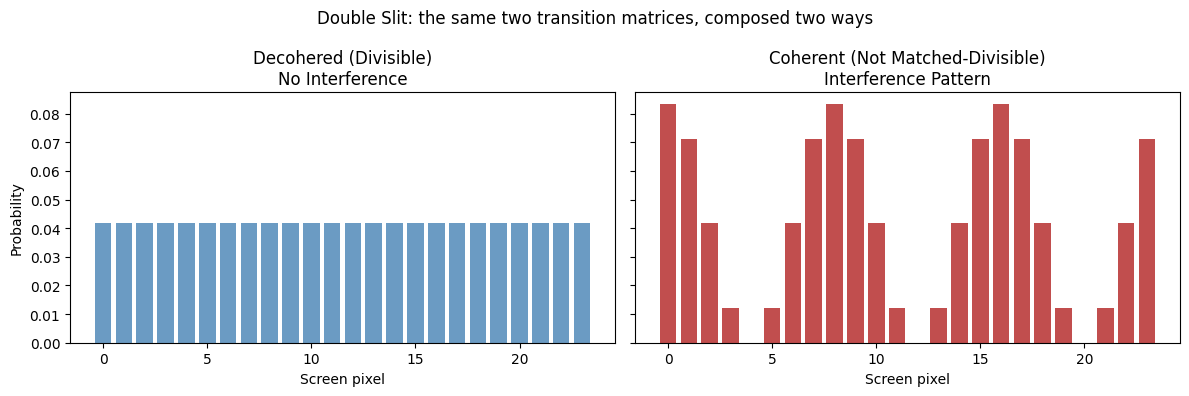

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.bar(k, p_classical, width=0.8, alpha=0.8, color='steelblue')
ax1.set_title('Decohered (Divisible)\nNo Interference')
ax1.set_xlabel('Screen pixel')
ax1.set_ylabel('Probability')

ax2.bar(k, p_quantum, width=0.8, alpha=0.8, color='firebrick')
ax2.set_title('Coherent (Not Matched-Divisible)\nInterference Pattern')
ax2.set_xlabel('Screen pixel')

plt.suptitle('Double Slit: the same two transition matrices, composed two ways')
plt.tight_layout()
plt.show()

### 📖 In depth: the cross term, and why it is the same object as indivisibility

Write $A_k$ and $B_k$ for the two slit amplitudes at screen pixel $k$. Then

$$p_{\text{classical}}(k) = \tfrac12\lvert A_k\rvert^2 + \tfrac12\lvert B_k\rvert^2,
\qquad
p_{\text{quantum}}(k) = \Big\lvert \tfrac{A_k+B_k}{\sqrt2} \Big\rvert^2
= \tfrac12\lvert A_k\rvert^2 + \tfrac12\lvert B_k\rvert^2 + \mathrm{Re}\,(A_k \overline{B_k})$$

$$\boxed{\;p_{\text{quantum}} - p_{\text{classical}} = \mathrm{Re}\,(A_k\overline{B_k})\;}$$

With the DFT propagator this evaluates in closed form to $\cos(2\pi k\Delta/n)/n$,
where $\Delta$ is the slit separation in modes — an honest cosine fringe, summing to
exactly zero over a full period.

#### The same algebra appears in the divisibility test

Compare notebook 03. There, the would-be division $\lvert U\rvert^2\lvert V\rvert^2$ differs from the true $\lvert UV\rvert^2$, and expanding shows why:

$$\Big\lvert \sum_k U_{ik}V_{kj}\Big\rvert^2
= \underbrace{\sum_k \lvert U_{ik}\rvert^2\lvert V_{kj}\rvert^2}_{\text{classical path sum}}
+ \underbrace{\sum_{k\neq l} U_{ik}V_{kj}\overline{U_{il}V_{lj}}}_{\text{cross terms}}$$

Sum over paths *then* square, versus square *then* sum over paths. The difference is a
cross term in both cases:

| double slit | divisibility |
|---|---|
| paths = slit A, slit B | paths = intermediate states $k$ |
| $p_{\text{qm}} - p_{\text{cl}} = \mathrm{Re}(A\overline{B})$ | $\lvert UV\rvert^2 - \lvert U\rvert^2\lvert V\rvert^2 = \text{cross terms}$ |
| makes fringes | makes $\lvert U\rvert^2\lvert V\rvert^2$ miss $\lvert UV\rvert^2$ |

**A matched-divisible process is one where you may sum over the intermediate state, using the
$\lvert U\rvert^2$ steps of Barandes' eq. 42, and be done.** Matched divisibility (section 7) *is* the
statement that summing over which-slit with the eq. 42 matrix $\lvert U_2\rvert^2$ is legitimate. Interference
is what you get when it is not. Whether *some other* stochastic middle step exists (Barandes'
eq. 6) is a separate question; section 7 shows it can have a different answer.

A likeness in form is not yet a demonstration. Section 4 supplies one: the two cross
terms are not merely similar in form, they are literally the same numbers.

<!-- expansion:05:papers-eq43 -->
### 📚 From the papers: interference as a divisibility discrepancy

* **The identity.** Defining $\Gamma(t\leftarrow t') = \lvert U(t\leftarrow t')\rvert^2$ with $U(t\leftarrow t') = U(t\leftarrow 0)U^\dagger(t'\leftarrow 0)$, Barandes writes "the discrepancy between the true transition matrix $\Gamma(t\leftarrow 0)$ and its would-be division $\Gamma(t\leftarrow t')\Gamma(t'\leftarrow 0)$" as $\sum_{k\neq l} U_{ik}\Psi_k\,\overline{U_{il}\Psi_l}$, with $\Psi(t') = U(t'\leftarrow 0)\mathbf e_j$. — *Stochastic-Quantum Correspondence, Section 3.5, Eqs. (39)–(43).* Here $U(t\leftarrow t') = U_2$ and, for the source column, only $k,l \in \{A,B\}$ survive: the two terms $(A,B)$ and $(B,A)$ add to the boxed $\mathrm{Re}(A_k\overline{B_k})$.
* **His reading.** "Interference is nothing more than a generic discrepancy between the actual indivisible stochastic dynamics and a heuristic-approximate divisible stochastic dynamics." For the double slit: "One cannot divide up the particle's evolution into, firstly, its transit from the emitter to the slits, and then, secondly, conditioned on which slit the particle enters, the particle's transit from the slits to the detection screen." — *same section.*
* **The hidden assumption.** In his lecture, Barandes says the usual multiply-and-sum-over-slits rule "does not follow from the general marginalization rules. It is not a mathematical identity. It implicitly requires making a Markovian or divisibility assumption." — *new-formulation lecture transcript, double-slit segment.* Footnote 13 of the paper aims the same point at Feynman's "It is not true that the electrons go either through hole 1 or hole 2."
* **A textbook echo.** Ballentine (Ch. 5, "Double slit diffraction") rejects the claim that the double slit breaks probability theory: the one-slit and two-slit probabilities are conditioned on different setups $C_1, C_2, C_3$, so $P(X|C_1)+P(X|C_2)\ne P(X|C_3)$ breaks no rule, and the inequality "may be contrary to classical mechanics, but it is quite compatible with classical probability theory." His fix (different conditions) differs from Barandes' (an indivisible process), but both blame the same step: adding one-slit probabilities.


<!-- expansion:05:derivation-cross-term -->
### 🧮 Worked derivation: from $\lvert\psi_A+\psi_B\rvert^2$ to the column of $D$

Write $A_k := U_2[k,A]$, $B_k := U_2[k,B]$.

**Coherent column.** $\Gamma(t_2,t_0)_{ks} = \big\lvert (A_k + B_k)/\sqrt2\big\rvert^2 = \tfrac12\lvert A_k\rvert^2 + \tfrac12\lvert B_k\rvert^2 + \tfrac12(A_k\overline{B_k} + \overline{A_k}B_k)$, and the last bracket is $2\,\mathrm{Re}(A_k\overline{B_k})$.

**Composed column.** $\Gamma(t_1,t_0)_{ms}$ is $\tfrac12$ at $m = A, B$ and $0$ elsewhere, so $[\Gamma(t_2,t_1)\Gamma(t_1,t_0)]_{ks} = \tfrac12\lvert A_k\rvert^2 + \tfrac12\lvert B_k\rvert^2$.

**Subtract.** $D_{ks} = \mathrm{Re}(A_k\overline{B_k})$: the per-path terms cancel, leaving only the cross term. For the DFT, $A_k\overline{B_k} = e^{2\pi i k(A-B)/n}/n$, so $D_{ks} = \cos(2\pi k\Delta/n)/n$.

**Why section 4 gets exactly `0.00e+00`.** `p_classical` is column `source` of `gamma_20_decohered`, which the code builds as `gamma_21 @ gamma_10`; `D[:, source]` subtracts the same product from the same coherent matrix. Identical floating-point operations in identical order give bit-identical results.


<!-- expansion:05:recap-2 -->
### 📝 Recap: section 2

* Coherent: $p(k) = (1 + \cos(2\pi k\Delta/n))/n$ — three bright fringes at twice the flat level, three exact zeros. Decohered: flat $1/n$.
* The difference is the cross term $\mathrm{Re}(A_k\overline{B_k})$, which sums to zero.
* Visibility is $1$ coherent, $\approx 0$ decohered.
* Barandes' Eq. (43) gives the same cross-term formula as the gap between a unistochastic process and its would-be division — interference without appeal to waves.


## 3. Divisibility, Tested on This Model

Notebooks 02 and 03 test divisibility by solving G(t2,t1) = G(t2,t0) inv(G(t1,t0)) and
looking for negative entries. That needs G(t1,t0) to be invertible, and here it never is.

If a unitary sends the source to the balanced superposition of slits A and B, then rows
A and B of U1 each have entry 1/sqrt(2) in the source column. Orthonormality of the rows
forces the Cauchy-Schwarz inequality on the remaining entries to be saturated, so those
row tails must be proportional, which makes rows A and B of abs(U1)^2 *identical*. The
matrix is rank-deficient for every balanced two-slit model. The inverse-based test is
not inconclusive here; it is unavailable.

So test the condition the way Barandes states it: does **any** valid stochastic matrix
G(t2,t1) satisfy G(t2,t0) = G(t2,t1) G(t1,t0)? That is a linear program, and needs no
inverse. The printed `defect` is the smallest L1 residual over all stochastic middle matrices.
Only zero versus non-zero matters: its size is not physical and depends on the arbitrary
completion of U1 (section 6).
For two configurations, Pimenta (arXiv:2505.08785, §III A) characterises divisibility geometrically,
singular G(t1,t0) included; the LP handles any number of configurations.

<!-- expansion:05:papers-inverse -->
### 📚 From the papers: why the inverse route is limited

* Barandes considers the construction notebooks 02–03 use: if $\Gamma(t'\leftarrow 0)$ is invertible, set $\tilde\Gamma = \Gamma(t\leftarrow 0)\,\Gamma^{-1}(t'\leftarrow 0)$. But "the inverse of a stochastic matrix can only be stochastic if both matrices are permutation matrices", so $\tilde\Gamma$ "is not generically stochastic". — *Stochastic-Quantum Correspondence, Section 3.5, Eqs. (37)–(38).* When the inverse exists, $\tilde\Gamma$ is the *only* solution, so its negative entries settle the question.
* When $\Gamma(t'\leftarrow 0)$ is singular, solutions may be many or none and an inverse cannot say which. Eq. (6) only asks whether a stochastic one *exists*, and that question survives singularity. (This singular-case framing is not a quotation from Barandes. Pimenta, arXiv:2505.08785, §III A, gives a complete geometric characterisation of divisibility for two configurations, singular $\Gamma(t'\leftarrow 0)$ included.)


### 📖 In depth: proof that the balanced double slit defeats the inverse-based test

This is worth stating carefully: it is a theorem, not a numerical accident, and that
decides which divisibility test can be used on this model.

**Claim.** Let $U$ be unitary with source column $U e_s = (e_A + e_B)/\sqrt2$. Then rows
$A$ and $B$ of $\lvert U\rvert^2$ are identical, so $\lvert U\rvert^2$ is singular.

**Proof.** Write $a$ for row $A$ of $U$ with the source entry deleted, and $b$ likewise
for row $B$. Both rows have $1/\sqrt2$ in the source column.

Rows of a unitary matrix are unit vectors, so
$\tfrac12 + \lVert a\rVert^2 = 1$, giving $\lVert a\rVert^2 = \lVert b\rVert^2 = \tfrac12$.

Rows of a unitary matrix are also orthogonal, so
$\tfrac{1}{\sqrt2}\cdot\overline{\tfrac{1}{\sqrt2}} + \langle a, b\rangle = 0$,
giving $\lvert\langle a, b\rangle\rvert = \tfrac12$.

But $\lVert a\rVert\,\lVert b\rVert = \tfrac{1}{\sqrt2}\cdot\tfrac{1}{\sqrt2} = \tfrac12$
as well. Cauchy-Schwarz is therefore an *equality*, which happens only when
$b = \lambda a$ for a scalar $\lambda$, necessarily with $\lvert\lambda\rvert = 1$.

Taking squared moduli entry by entry, $\lvert U_{Bj}\rvert^2 = \lvert U_{Aj}\rvert^2$
for every $j$ — including the source column, where both are $\tfrac12$. The two rows of
$\lvert U\rvert^2$ coincide. $\blacksquare$

Two consequences worth noticing:

1. **This has nothing to do with numerical tolerance.** No choice of `tol` rescues it,
   and no cleverer completion of $U_1$ avoids it. Any *balanced* two-slit model has a
   rank-deficient first transition matrix.
2. **It is a limitation of the test, not of the physics.** Divisibility asks whether a
   valid intermediate matrix *exists*. Solving by inverse is one way to look for it, and
   it happens to be a way that requires invertibility. Barandes' condition itself does
   not.

Hence `check_divisibility_lp()` in `isp/divisibility.py`, which asks the existence
question directly as a linear program:

$$\text{find } M \;\text{ s.t. }\; M\,\Gamma(t_1,t_0) = \Gamma(t_2,t_0),
\quad M \geq 0, \quad \mathbf{1}^{\mathsf T}M = \mathbf{1}^{\mathsf T}$$

Feasible means divisible; infeasible means indivisible. No inverse appears, so
singularity is simply irrelevant.

<!-- expansion:05:derivation-lp -->
### 🧮 Worked derivation: how the linear-program test is built

`_intermediate_lp()` in `isp/divisibility.py` turns "does a stochastic $M$ exist with $M\,\Gamma(t_1,t_0) = \Gamma(t_2,t_0)$?" into a standard LP.

* **Unknowns:** the $n^2 = 576$ entries of $M$, stacked row by row: $x_{kn+m} = M_{km}$.
* **Reproduce the process:** row $k$ of $MT$ (with $T = \Gamma(t_1,t_0)$) is $T^{\mathsf T}$ applied to row $k$ of $M$, so all 576 equations together read $(I_n \otimes T^{\mathsf T})\,\mathbf x = \mathrm{vec}\,\Gamma(t_2,t_0)$.
* **Columns of $M$ sum to 1:** $(\mathbf 1^{\mathsf T}\otimes I_n)\,\mathbf x = \mathbf 1$ (24 equations).
* **Non-negativity:** $\mathbf x \ge 0$.
* **Objective:** none in this strict form, which only asks whether a feasible $M$ exists. No inverse, so rank $23$ of $24$ is irrelevant.

**The defect, which is what the verdict uses.** `check_divisibility_lp()` does not use the solver's feasible/infeasible answer. It solves the residual form below and calls the process divisible when the minimal $L_1$ residual is $\le 10^{-8}$ (`tol`); the witness is the minimising $M$. Add slacks $\mathbf s^\pm \ge 0$, relax the first constraint to $(I\otimes T^{\mathsf T})\mathbf x - \mathbf s^+ + \mathbf s^- = \mathrm{vec}\,\Gamma(t_2,t_0)$, and minimise $\mathbf 1^{\mathsf T}(\mathbf s^+ + \mathbf s^-)$ over 1728 variables. The optimum is $\min_M \lVert M\,\Gamma(t_1,t_0) - \Gamma(t_2,t_0)\rVert_1$: always feasible, zero exactly when the strict LP is feasible.

**Caveat.** The residual is computed by a floating-point solver with tolerances. "Exact" here means the condition is tested directly, not in rational arithmetic; a process within a hair of the divisible set could be misclassified. At $c = 1$ the minimum residual is about 12, far from that boundary. As $c \to 0$ the residual shrinks (about $0.0015$ at $c = 0.001$), and there the solver's verdict is backed by an exact argument that needs no solver: the null-vector check at the end of section 4.


In [6]:
g10 = m['gamma_10']
print('the inverse-based test is structurally unavailable:')
print(f'  rows A and B of abs(U1)^2 identical: {np.allclose(g10[m["slit_a"]], g10[m["slit_b"]])}')
print(f'  rank abs(U1)^2 = {np.linalg.matrix_rank(g10)} of {n}')
print()

for coherence in (1.0, 0.0):
    proc = make_double_slit_process(coherence=coherence)
    result = check_divisibility_lp(proc)
    label = 'coherent' if coherence else 'decohered'
    print(f'{label:10s} (coherence={coherence}):')
    print(f'  divisible    = {result["divisible"]}')
    print(f'  failure_mode = {result["failure_mode"]}')
    print(f'  defect       = {result["defect"]:.6f}')

witness = check_divisibility_lp(make_double_slit_process(coherence=0.0))['witness']
print()
print('the decohered process has a valid intermediate matrix:')
print(f'  non-negative: {witness.min() >= -1e-9}')
print(f'  columns sum to 1: {np.allclose(witness.sum(axis=0), 1)}')
print(f'  and abs(U2)^2 is itself one such solution: '
      f'{np.allclose(m["gamma_21"] @ g10, m["gamma_20_decohered"])}')

the inverse-based test is structurally unavailable:
  rows A and B of abs(U1)^2 identical: True
  rank abs(U1)^2 = 23 of 24

coherent   (coherence=1.0):
  divisible    = False
  failure_mode = no_valid_intermediate_matrix
  defect       = 11.998165
decohered  (coherence=0.0):
  divisible    = True
  failure_mode = None
  defect       = 0.000000

the decohered process has a valid intermediate matrix:
  non-negative: True
  columns sum to 1: True
  and abs(U2)^2 is itself one such solution: True


<!-- expansion:05:howto-lp -->
### 🧭 How to use this cell / what to look at

**What it computes.** The obstruction on the real model (rows A, B identical; rank `23 of 24`), the LP verdict at $c = 1$ and $c = 0$, and checks on the decohered witness.

**Numbers that matter.** Coherent: `divisible = False`, `no_valid_intermediate_matrix`. Decohered: `divisible = True`, `defect = 0.000000`, witness non-negative with unit column sums, and $\lvert U_2\rvert^2$ itself also works. The coherent `defect = 11.998165` is a **yes/no flag**, not a size (see section 4's last in-depth cell and section 6).

**Try this.**

1. Run the LP at `coherence=0.02`. *Prediction:* still `False`; the verdict flips only at $c = 0$.
2. Compare `witness` with `m['gamma_21']`. *Prediction:* they need not match. With singular $\Gamma(t_1,t_0)$ the solution is not unique — which is why the cell checks $\lvert U_2\rvert^2$ separately.


In [7]:
# 🔍 Reading the code: the theorem above, checked at several sizes, and the old test
#    hitting the wall it cannot get past.
#
#    Smallest singular value rather than determinant: det underflows to zero for
#    any large matrix with small entries, which would confuse a genuine rank
#    deficiency with an artefact of scale.

print('rows A and B of abs(U1)^2 coincide at every size:')
for size in (6, 8, 16, 24, 32):
    G = np.abs(slit_preparation(size, 1, size - 2))**2
    smallest = np.linalg.svd(G, compute_uv=False)[-1]
    print(f'  n={size:2d}:  rows identical {np.allclose(G[1], G[size - 2])},  '
          f'rank {np.linalg.matrix_rank(G):2d} of {size},  '
          f'smallest singular value {smallest:.2e}')

print()
print('what the inverse-based test reports if you force it through:')
legacy = StochasticProcess(states=[str(i) for i in range(n)],
                           transitions=[g10, np.eye(n)], times=[0.0, 1.0, 2.0])
legacy_result = check_divisibility(legacy)
print(f'  divisible    = {legacy_result["divisible"]}')
print(f'  failure_mode = {legacy_result["failure_mode"]}')
print('  ^ that is not a physics verdict, it is the test declining to answer')
print()
print('the LP test answers on the same matrices, both ways:')
print(f'  coherent  -> divisible '
      f'{check_divisibility_lp(make_double_slit_process(coherence=1.0))["divisible"]}')
print(f'  decohered -> divisible '
      f'{check_divisibility_lp(make_double_slit_process(coherence=0.0))["divisible"]}')

rows A and B of abs(U1)^2 coincide at every size:
  n= 6:  rows identical True,  rank  5 of 6,  smallest singular value 8.18e-18
  n= 8:  rows identical True,  rank  7 of 8,  smallest singular value 2.77e-17
  n=16:  rows identical True,  rank 15 of 16,  smallest singular value 1.57e-17
  n=24:  rows identical True,  rank 23 of 24,  smallest singular value 9.69e-18
  n=32:  rows identical True,  rank 31 of 32,  smallest singular value 2.55e-17

what the inverse-based test reports if you force it through:
  divisible    = None
  failure_mode = singular_matrix
  ^ that is not a physics verdict, it is the test declining to answer

the LP test answers on the same matrices, both ways:
  coherent  -> divisible False


  decohered -> divisible True


<!-- expansion:05:howto-sizes -->
### 🧭 How to use this cell / what to look at

**What it computes.** The equal-rows theorem at $n = 6$ to $32$; the legacy inverse test forced through; the LP on the same matrices.

**Numbers that matter.** Rank is always $n - 1$, with smallest singular value $\sim10^{-17}$ (`9.69e-18` at $n = 24$) — floating-point zero. The legacy test prints `divisible = None` with `failure_mode = singular_matrix`: undecided. It means "could not run", not "indivisible". The LP then answers both ways.

**Try this.** Run the legacy `check_divisibility()` on a `StochasticProcess` with transitions `[gamma_10, gamma_21]` — the decohered, *divisible* process. *Prediction:* `singular_matrix` again, with `divisible = None`. The inverse test cannot tell this divisible process from the indivisible coherent one; only the LP can.


### 📖 In depth: rank 23 of 24 — one lost dimension, and where it sits

The proof above shows $\Gamma(t_1,t_0) = |U_1|^2$ is singular for any balanced two-slit model. Singular is a binary statement; the useful question is *how* singular, and in *which direction*. Both answers are sharp.

#### How much rank is lost: exactly one

Numerically, $\operatorname{rank}\big(\Gamma(t_1,t_0)\big) = 23$ out of $24$. Not a badly degenerate matrix — a matrix missing precisely one dimension. The determinant is $\approx -1.9 \times 10^{-37}$, which is zero to any reasonable tolerance, but the near-singularity is not spread across many small singular values. One direction is annihilated and the other twenty-three are fine.

#### Which direction, on the output side: the difference of the two slits

The proof established that rows $A$ and $B$ of $|U_1|^2$ are identical. Written as a statement about the left null space, that is

$$\big(\mathbf e_A - \mathbf e_B\big)^{\mathsf T}\,\Gamma(t_1,t_0) \;=\; \mathbf 0^{\mathsf T}$$

and the check confirms it to $5 \times 10^{-17}$. The left null space is one-dimensional and spanned by $\mathbf e_A - \mathbf e_B$.

Read that vector as an observable on the slit plane, *"slit A minus slit B"*. Equal rows mean every source mode reaches A and B with equal probability, so after one step this observable averages to zero whatever the source distribution.

> **What this does and does not say.** The left null vector lives on the slit (output) side. It comes from Cauchy–Schwarz saturating: a balanced superposition sends equal amplitude to both slits, and equal amplitudes give equal probability rows. The *input* direction that an inverse would have to recover is a different vector: the right null vector $\mathbf w$ with $\Gamma(t_1,t_0)\,\mathbf w = \mathbf 0$ (section 4's last in-depth cell). It lives in the source space and depends on the arbitrary completion of $U_1$. So calling the lost dimension "the which-path distinction" would overread it.

#### Why this is the right diagnosis rather than a numerical complaint

It explains why the inverse-based test of notebooks 02 and 03 cannot run on this model. Not because of floating point, or an unlucky parameter, or a matrix that happens to be awkward at $n = 24$. It failed because **the classical description of this experiment has genuinely lost the information the test needs**, structurally, at every model size — and inverting a matrix means recovering an input from an output, which is impossible along the right null vector $\mathbf w$.

$$\textbf{balanced slits} \;\Rightarrow\; \textbf{equal rows} \;\Rightarrow\; \textbf{rank deficient (left null vector } \mathbf e_A - \mathbf e_B\textbf{)} \;\Rightarrow\; \textbf{no inverse, at any } n$$

The linear program does not need to recover anything. It asks whether some legal matrix exists, and existence is a question a rank-deficient $\Gamma$ can still answer.

<!-- expansion:05:recap-3 -->
### 📝 Recap: section 3

* For any balanced two-slit preparation, rows A and B of $\lvert U_1\rvert^2$ coincide (Cauchy–Schwarz saturates): rank $n-1$, no inverse. The lost direction is $\mathbf e_A - \mathbf e_B$, the which-slit distinction.
* Barandes' Eq. (6) is an existence question, which an LP in $n^2$ unknowns answers without inverting anything.
* Coherent: indivisible. Decohered: divisible, with a valid witness.
* The LP `defect` is a minimum $L_1$ residual — a verdict, not a physical magnitude.


## 4. Barandes's Eq. 43 on This Model: the Fringes and the Divisibility Defect

Define the defect matrix

    D = G(t2,t0) - G(t2,t1) G(t1,t0)

which is zero exactly when the process composes classically through G(t2,t1) = abs(U2)^2.
Its source column is the interference pattern, exactly, not approximately. This is Barandes's eq. 43
(Paper 1, §3.5, p. 14), reproduced here on this model: he writes the discrepancy between Γ(t←0) and
its "would-be division" Γ(t←t′)Γ(t′←0) as a sum of cross terms, and on the source column those cross
terms are the fringes.

max abs( (p_quantum - p_classical) - D[:, source] ) = 0.00e+00

D[:, source] goes negative at 9 of 24 pixels
  below the flat 1/n level (the dark side of each fringe)
D ranges from -0.041667 to 0.215282


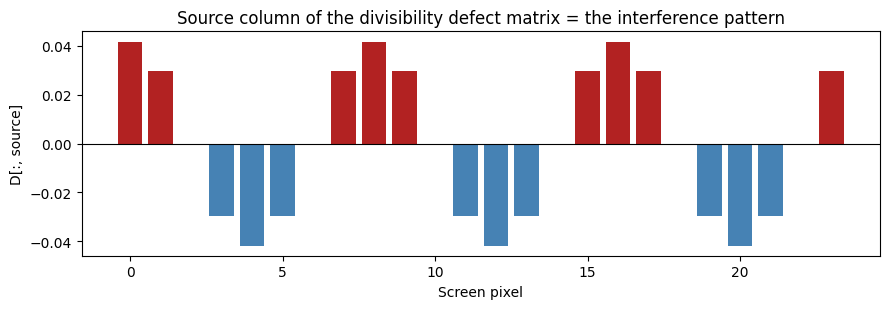

In [8]:
D = m['gamma_20_coherent'] - m['gamma_21'] @ m['gamma_10']

print(f'max abs( (p_quantum - p_classical) - D[:, source] ) = '
      f'{np.abs(interference - D[:, source]).max():.2e}')
print()
print(f'D[:, source] goes negative at {(D[:, source] < -1e-12).sum()} of {n} pixels')
print('  below the flat 1/n level (the dark side of each fringe)')
print(f'D ranges from {D.min():.6f} to {D.max():.6f}')

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(k, D[:, source], width=0.8,
       color=np.where(D[:, source] >= 0, 'firebrick', 'steelblue'))
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Screen pixel')
ax.set_ylabel('D[:, source]')
ax.set_title('Source column of the divisibility defect matrix = the interference pattern')
plt.tight_layout()
plt.show()

<!-- expansion:05:howto-defect -->
### 🧭 How to use this cell / what to look at

**What it computes.** The full $24\times24$ defect matrix, the comparison of its source column with section 2's interference term, the negative-entry count, and a bar chart.

**Numbers that matter.**

* `0.00e+00`: bit-for-bit equality (see the worked derivation in section 2).
* `9 of 24` negative pixels: $\cos(\pi k/4) < 0$ at $k \equiv 3, 4, 5 \pmod 8$, three per period, three periods. Pixels at exactly zero ($k \equiv 2, 6$) are correctly not counted.
* Range `-0.041667` to `0.215282`. The minimum is $-1/24$, the trough of the source-column cosine. The maximum is **not** in the source column, which peaks at $+1/24$; it sits in a completion column.

**Try this.** Compute `np.abs(D[:, source]).sum()`. *Prediction:* $(1+\sqrt2)/4 \approx 0.603553$. Per 8-pixel period $\sum\lvert\cos(\pi k/4)\rvert = 2 + 2\sqrt2$; three periods over $n = 24$ give $(1+\sqrt2)/4$ — the seed-independent number in section 6.


### 📖 In depth: what that identity does and does not establish

The number printed above is `0.00e+00` — not "small", but bit-for-bit equal. That is not
a coincidence, and it is worth being precise about why, because the strength of the whole
notebook rests on it.

The source column of $\Gamma(t_2,t_0)$ is, by construction,
$\lvert U_2 U_1 e_s\rvert^2 = \lvert (A+B)/\sqrt2 \rvert^2 = p_{\text{quantum}}$.
The source column of the product $\Gamma(t_2,t_1)\Gamma(t_1,t_0)$ is
$\sum_m \lvert U_2[\cdot,m]\rvert^2\,\lvert U_1[m,s]\rvert^2
= \tfrac12\lvert A\rvert^2 + \tfrac12\lvert B\rvert^2 = p_{\text{classical}}$.
Subtracting gives the identity. Both sides are the *same* cross term written in two
notations — one optical, one stochastic.

So the claim "interference is the matched-divisibility defect" does real work here rather than gesturing:

* it is an equation between computed arrays, not a resemblance between two stories;
* both sides come from one model, sharing every variable;
* and it explains the *sign* structure — each column of $D$ sums to zero, so probability
  added at the bright fringes is taken from the dark ones, and $D[:,s]$ is negative exactly
  where the coherent pattern falls below the flat classical $1/n$. (These are negative
  entries of a *difference* of two stochastic matrices, a different object from the
  negative entries notebooks 02 and 03 look for in a solved intermediate matrix.)

**What it does not establish.** This is an identity about one particular model, not a
proof of Barandes' correspondence — the exact correspondence between indivisible
stochastic processes and quantum theory, which is argued in his papers, not here. What
this notebook shows is that in a concrete double slit the two phenomena are the same
numbers. The identity concerns $D$, the gap to the which-path composition through
$\lvert U_2\rvert^2$; the separate fact that no stochastic middle step exists at all is a
property of the full matrix (two cells below).

### 📖 In depth: only one column of $D$ is physics — about 3% of the whole matrix

Section 4 reads the interference pattern off the **source column** of the defect matrix. It is worth being explicit that the rest of $D$ is not a smaller version of the same thing, because a number computed from the whole matrix appears elsewhere in this repo and is easy to misquote.

#### Only the source column is physical

`slit_preparation()` builds a unitary whose *source* column is the balanced superposition $(|A\rangle + |B\rangle)/\sqrt 2$. Its docstring is candid about the rest:

```python
# Only that one column carries physical content -- it is what a particle
# emitted from the source actually does. The remaining columns are an
# arbitrary orthonormal completion, required because a process needs a
# full transition matrix.
```

The completion comes from a QR factorization of a seeded random matrix. It has to be *something* — a transition matrix needs every column — but nothing in the experiment corresponds to it. Section 6 confirms this the right way, by changing the seed and watching the predictions stay put.

Since $D$ inherits that structure, the same split applies to it: **column $s$ is the double slit; the other twenty-three columns are the arbitrary completion, differenced.**

#### The numbers, and the warning they carry

| quantity | value |
|---|---|
| $L_1$ norm of the source column, $\;\lVert D[:,s]\rVert_1$ | $0.603553$ |
| $L_1$ norm of the entire matrix, $\;\lVert D \rVert_1$ | $17.699479$ |
| fraction of the total living in the physical column | $\mathbf{3.4\%}$ |
| largest entry anywhere in $D$ | $0.215282$ — **not** in the source column |

More than ninety-six per cent of the whole-matrix defect comes from columns that describe nothing. The single largest entry of $D$ is one of them.

> ⚠️ **So `divisibility_defect()`'s $11.998165$ must never be quoted as a physical magnitude.** It is a legitimate *verdict* — non-zero means no valid intermediate matrix exists, with no inverse needed — and it is the right tool for that job. But it aggregates over the arbitrary completion, so its size reflects the model's padding far more than its physics. A different seed, or a different number of modes, moves it.
>
> (It is also a different quantity from $\lVert D\rVert_1 = 17.699479$ above. The defect returned by the LP is the *minimum* achievable residual over all valid stochastic $M$, not the residual of the one particular classical product $\Gamma(t_2,t_1)\Gamma(t_1,t_0)$. The LP does better than that product, which is why its number is smaller.)

#### The contrast worth carrying

$$\underbrace{D[:,s]}_{\textbf{physics — equals the fringe pattern, to } 0.00\text{e}{+}00} \qquad\qquad \underbrace{\text{the LP defect}}_{\textbf{verdict only — indivisible, yes or no}}$$

One column of this matrix is a measurable prediction. The LP defect is a boolean wearing a decimal point. $\lVert D\rVert_1$ is neither: it measures how far one particular middle step, $\lvert U_2\rvert^2$, misses on the arbitrary completion, and a non-zero value alone does not show that every middle step fails.

<!-- expansion:05:indepth-verdict-columns -->
### 📖 In depth: which columns the yes/no verdict rests on

The cell above separates the physical column of $D$ from the completion. The same split applies to the LP **verdict**.

**The source column alone can always be matched.** Restricted to that column, we need a stochastic $M$ with

$$M\,\Gamma(t_1,t_0)\,\mathbf e_s = \tfrac12\big(M\mathbf e_A + M\mathbf e_B\big) = \mathbf p_{\text{quantum}} .$$

Set columns $A$ and $B$ of $M$ both equal to $\mathbf p_{\text{quantum}}$ and fill the rest with anything stochastic. It works. So the fringe pattern on its own *is* reproducible by some stochastic middle step — just not by $\lvert U_2\rvert^2$.

**The full process cannot be matched, and one vector shows why.** $\Gamma(t_1,t_0)$ has rank 23, so besides the left null vector $\mathbf e_A - \mathbf e_B$ of section 3 it has a right null vector $\mathbf w$ with $\Gamma(t_1,t_0)\,\mathbf w = \mathbf 0$. Any $M$ at all, stochastic or not, with $M\,\Gamma(t_1,t_0) = \Gamma(t_2,t_0)$ would force $\Gamma(t_2,t_0)\,\mathbf w = \mathbf 0$. The columns of $\Gamma(t_1,t_0)$ sum to 1, so the entries of $\mathbf w$ sum to 0, and the decohered part (every entry $1/n$) sends $\mathbf w$ to zero. That leaves

$$\Gamma_c(t_2,t_0)\,\mathbf w = c\,\lvert U_2U_1\rvert^2\,\mathbf w .$$

For a unit $\mathbf w$, $\lVert\,\lvert U_2U_1\rvert^2\mathbf w\rVert$ is $0.174$ at seed 7; section 6 prints it for all five seeds. So for every $c > 0$ the defining equation has no solution of any kind, and the LP's `no_valid_intermediate_matrix` follows from linear algebra before positivity is even reached. To check it: `w = np.linalg.svd(m['gamma_10'])[2][-1]`, then `np.linalg.norm(m['gamma_20_coherent'] @ w)`.

**What rests on what.** *Fringes $= D[:,s]$* depends on no arbitrary choice. *No valid $M$ exists* is a property of the full transition matrix, which Barandes' definition requires; $\mathbf w$ depends on the completion, so this is checked completion by completion (five here), not proved for all. "The fringes are the divisibility defect" refers to $D$, the gap to the which-path composition through $\lvert U_2\rvert^2$ — the quantity in Barandes' Eq. (43).


<!-- expansion:05:recap-4 -->
### 📝 Recap: section 4

* The source column of $D$ equals the interference term to `0.00e+00`; it is negative exactly where the coherent pattern falls below the flat $1/n$, around each dark fringe; its $L_1$ norm is $(1+\sqrt2)/4$.
* This is Barandes' Eq. (43) on a concrete model.
* Whole-matrix magnitudes ($\lVert D\rVert_1$, LP defect, max entry) mostly reflect the arbitrary completion. Only the LP defect carries a verdict, and only as zero versus non-zero.
* The fringe identity uses one column; the indivisibility verdict uses all of them. A right null vector $\mathbf w$ of $\Gamma(t_1,t_0)$ with $\Gamma(t_2,t_0)\mathbf w \ne \mathbf 0$ rules out every middle step, for every $c > 0$, for this completion. Whether such a $\mathbf w$ exists depends on the completion (section 7).


## 5. Interference and Indivisibility Together, on This Model

Dephase at the slit plane: multiply every off-diagonal entry of the density matrix ρ, in the
mode basis, by c. Doing this for every input column of U1 and propagating gives

    G_c(t2,t0) = (1 - c) G(t2,t1) G(t1,t0)  +  c abs(U2 U1)^2

so c = 1 is a fully coherent particle and c = 0 is a which-path measurement.
Sweep c and measure both quantities on the same process.

The sweep checks 21 values of c, but the verdict holds for every c > 0. G(t1,t0) is rank-deficient,
so it has a right null vector w with G(t1,t0) w = 0. Any middle step M would then force
G_c(t2,t0) w = M G(t1,t0) w = 0. The decohered part sends w to zero, so G_c(t2,t0) w = c abs(U2 U1)^2 w,
which the cell prints as non-zero for this completion. So no middle step exists for any c > 0,
for this completion (section 6 repeats the check on others).

### 📖 In depth: the interpolation is derived, not assumed

A convex mixture of the coherent and decohered processes could look like a convenient
device chosen to make the plot come out right. It is not — it falls out of applying an
ordinary dephasing channel at the slit plane.

Start a particle in mode $j$. After $U_1$ its state is $\psi = U_1 e_j$, with density
matrix $\rho_{mn} = \psi_m\overline{\psi_n}$. A which-path measurement of strength
$1-c$ suppresses the off-diagonal entries in the slit-plane mode basis:

$$\rho_{mn} \;\longmapsto\; \rho_{mn}\big(\delta_{mn} + c\,(1 - \delta_{mn})\big)$$

Propagating with $U_2$ and reading off the screen probability at pixel $k$:

$$\Gamma_c[k,j] = \sum_{m,n} U_2[k,m]\,\rho_{mn}\big(\delta_{mn} + c(1-\delta_{mn})\big)\,\overline{U_2[k,n]}$$

Split the sum into its diagonal and off-diagonal parts and re-assemble:

$$\Gamma_c[k,j] = (1-c)\sum_m \lvert U_2[k,m]\rvert^2\lvert U_1[m,j]\rvert^2
\;+\; c\,\Big\lvert \sum_m U_2[k,m]U_1[m,j] \Big\rvert^2$$

$$= (1-c)\,\big(\lvert U_2\rvert^2\lvert U_1\rvert^2\big)[k,j] \;+\; c\,\lvert U_2U_1\rvert^2[k,j]$$

which is the mixture, for every input mode $j$, not merely for the source column. The
coherence $c$ is a physical parameter — how much which-path information leaked — and the
linear interpolation is its consequence.

Two things then follow, and the sweep below checks both:

* **fringe visibility is exactly $c$**, since $p_c(k) = (1 + c\cos(2\pi k\Delta/n))/n$;
* **the process is divisible precisely at $c = 0$**: at $c=0$ the composed matrix *is* the
  product, so $\lvert U_2\rvert^2$ is a valid middle step; for $c > 0$ no valid intermediate
  matrix exists for the full process. The sweep checks this by LP at 21 values of $c$, and
  the null-vector argument at the end of section 4 extends it to every $c$ in $(0, 1]$ for
  each completion tested.

So on this model, with this completion, interference and indivisibility appear together in both
directions. Section 7 shows that this is a property of the completion, not a law: on a fine-tuned
completion a partly dephased process ($c \le 1/2$) shows fringes and is still divisible, though the
fully coherent one is not.

<!-- expansion:05:papers-decoherence -->
### 📚 From the papers: recording the slit makes the process divisible

* In "Division events and the Markov approximation", Barandes couples a system to an environment that ends in "an idealized statistical correlation between the configuration $i'$ of the subject system at $t'$ and the corresponding configuration $e(i')$ of the environment" (Eq. 45). Marginalising over the environment kills the cross terms, giving $p^S_i(t) = \sum_{i'}\lvert U^S_{ii'}(t\leftarrow t')\rvert^2 p^S_{i'}(t')$, so the transition matrix is "manifestly divisible at $t'$". — *Stochastic-Quantum Correspondence, Section 3.7, Eqs. (44)–(56).*
* **Mapping.** A which-path detector is such an environment; a perfect record is $c = 0$, making $t_1$ a division event. Reading intermediate $c$ as an imperfect record is this notebook's modelling choice (see the `double_slit_matrices()` docstring), not a formula from the paper.
* **Beyond quantum systems.** Barandes conjectures that discrepancies between any indivisible or non-Markovian system and its "heuristic-approximate divisible or Markovian approximation" can be read "as manifestations of interference". — *Section 3.6.* This notebook tests only the quantum double slit.


In [9]:
coherences = np.linspace(0, 1, 21)
visibility, column_defect, divisible = [], [], []

for c in coherences:
    mc = double_slit_matrices(coherence=c)
    p = screen_distribution(mc)
    visibility.append(fringe_visibility(p))
    column_defect.append(np.abs(p - screen_distribution(mc, 'gamma_20_decohered')).sum())
    divisible.append(check_divisibility_lp(make_double_slit_process(coherence=c))['divisible'])

visibility = np.array(visibility)
column_defect = np.array(column_defect)
divisible = np.array(divisible)

print(f'visibility equals the coherence exactly: max error {np.abs(visibility - coherences).max():.2e}')
print(f'divisible only at c = {coherences[divisible]}')
print(f'interference present wherever indivisible: {np.all(visibility[~divisible] > 1e-12)}')
print(f'no interference wherever divisible:        {np.all(visibility[divisible] < 1e-12)}')

w = np.linalg.svd(m['gamma_10'])[2][-1]
print()
print('every c > 0, not just the grid: right null vector w of G(t1,t0)')
print(f'  norm of G(t1,t0) w        = {np.linalg.norm(m["gamma_10"] @ w):.1e}')
print(f'  norm of abs(U2 U1)^2 w    = {np.linalg.norm(m["gamma_20_coherent"] @ w):.4f}  (non-zero)')

visibility equals the coherence exactly: max error 2.50e-16
divisible only at c = [0.]
interference present wherever indivisible: True
no interference wherever divisible:        True

every c > 0, not just the grid: right null vector w of G(t1,t0)
  norm of G(t1,t0) w        = 9.9e-17
  norm of abs(U2 U1)^2 w    = 0.1744  (non-zero)


<!-- expansion:05:howto-sweep -->
### 🧭 How to use this cell / what to look at

**What it computes.** For $c = 0, 0.05, \ldots, 1$: fringe visibility, the $L_1$ size of the source-column defect, and the LP verdict (21 LPs).

**Numbers that matter.** Visibility equals $c$ to `2.50e-16`: from $p_c = (1 + c\cos(\cdot))/n$, $V = \big((1+c) - (1-c)\big)/\big((1+c) + (1-c)\big) = c$. Divisible only at `[0.]`. Both directions ("interference wherever indivisible", "none wherever divisible") print `True` for this completion.

**In the plot below,** both curves are straight lines through the origin: visibility $= c$, column defect $= c\,(1+\sqrt2)/4 \approx 0.6036\,c$. Only where they hit zero matters; the slope ratio is a property of this fringe shape. The LP defect is deliberately not plotted — its height depends on the seed.

**Between grid points.** A 21-point grid alone cannot rule out divisibility in $(0, 0.05)$. Algebra does. For the source column, the defect is $c$ times a fixed non-zero cosine. For the full process, section 4's null vector gives $\Gamma_c(t_2,t_0)\,\mathbf w = c\,\lvert U_2U_1\rvert^2\mathbf w \ne \mathbf 0$ for every $c > 0$, so no middle step exists anywhere in $(0, 1]$ for this completion. The cell's last two lines print this check: $\lVert\Gamma(t_1,t_0)\mathbf w\rVert \approx 10^{-16}$ and $\lVert\,\lvert U_2U_1\rvert^2\mathbf w\rVert = 0.1744$.

**Try this.** Sweep `np.linspace(0, 0.05, 11)`. *Prediction:* divisible only at $c = 0$; visibility still equals $c$.


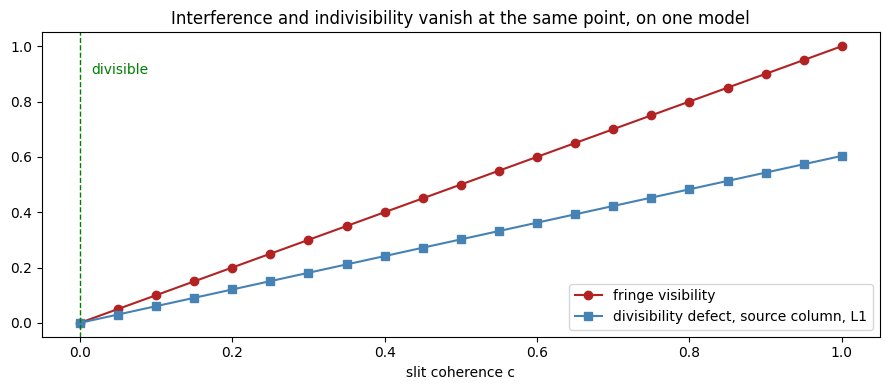

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(coherences, visibility, 'o-', color='firebrick', label='fringe visibility')
ax.plot(coherences, column_defect, 's-', color='steelblue',
        label='divisibility defect, source column, L1')
ax.axvline(0, color='green', linestyle='--', linewidth=1)
ax.annotate('divisible', xy=(0.015, 0.9), color='green')
ax.set_xlabel('slit coherence c')
ax.set_title('Interference and indivisibility vanish at the same point, on one model')
ax.legend()
plt.tight_layout()
plt.show()

<!-- expansion:05:recap-5 -->
### 📝 Recap: section 5

* Dephasing the slit-plane density matrix by $c$ gives $\Gamma_c = (1-c)\lvert U_2\rvert^2\lvert U_1\rvert^2 + c\,\lvert U_2U_1\rvert^2$ for every input — derived, not assumed.
* Visibility $= c$ exactly; this completion is divisible only at $c = 0$. The LP shows it on the grid, and the null vector of $\Gamma(t_1,t_0)$ extends it to every $c > 0$. Section 7 shows a fine-tuned completion where this fails for $0 < c \le 1/2$, though not at $c = 1$.
* Barandes' Section 3.7 derives the $c = 0$ case from an environment that records the configuration. Notebook 06 takes this up.


## 6. The Prediction Does Not Depend on the Arbitrary Part of the Model

Only the source column of U1 is physical. The remaining columns are an arbitrary
orthonormal completion, needed because a process requires a full transition matrix.
Vary that completion and check that nothing observable moves.

What this does and does not show. The screen distributions use only the physical source column, so they cannot
change. The divisibility verdict uses the whole matrix. The source column on its own can always be matched by a valid
intermediate step: give slits A and B the coherent screen distribution as their columns. So "indivisible" is a statement
about the full process, and here it is confirmed for these five completions, not proved for all of them.
For each completion the cell also repeats section 5's null-vector check, so the verdict covers every c > 0,
not only c = 1.
Section 7 shows why that caveat matters.


In [11]:
reference = double_slit_matrices(seed=7)

for seed in (1, 7, 42, 99, 2026):
    ms = double_slit_matrices(seed=seed)
    same = all(np.allclose(screen_distribution(ms, key), screen_distribution(reference, key))
               for key in ('gamma_20_coherent', 'gamma_20_decohered'))
    verdict = check_divisibility_lp(make_double_slit_process(seed=seed))['divisible']
    w = np.linalg.svd(ms['gamma_10'])[2][-1]   # section 5's null vector, for this completion
    print(f'seed {seed:5d}: identical screen distributions {same},  divisible {verdict}')
    print(f'             null vector: norm G(t1,t0) w = {np.linalg.norm(ms["gamma_10"] @ w):.1e},  '
          f'norm abs(U2 U1)^2 w = {np.linalg.norm(ms["gamma_20_coherent"] @ w):.4f}')

seed     1: identical screen distributions True,  divisible False
             null vector: norm G(t1,t0) w = 9.8e-17,  norm abs(U2 U1)^2 w = 0.1887
seed     7: identical screen distributions True,  divisible False
             null vector: norm G(t1,t0) w = 9.9e-17,  norm abs(U2 U1)^2 w = 0.1744
seed    42: identical screen distributions True,  divisible False
             null vector: norm G(t1,t0) w = 2.0e-16,  norm abs(U2 U1)^2 w = 0.1988
seed    99: identical screen distributions True,  divisible False
             null vector: norm G(t1,t0) w = 1.4e-16,  norm abs(U2 U1)^2 w = 0.1992


seed  2026: identical screen distributions True,  divisible False
             null vector: norm G(t1,t0) w = 1.3e-16,  norm abs(U2 U1)^2 w = 0.1917


<!-- expansion:05:howto-seeds -->
### 🧭 How to use this cell / what to look at

**What it computes.** Five seeds = five random completions of $U_1$'s 23 non-physical columns. Each is checked against the seed-7 screen distributions, and the LP verdict is recomputed.

**What to look at.** Every seed reads `identical screen distributions True, divisible False`, and its second line repeats section 5's null-vector check: $\lVert\Gamma(t_1,t_0)\mathbf w\rVert \sim 10^{-16}$ and a non-zero $\lVert\,\lvert U_2U_1\rvert^2\mathbf w\rVert$, so for each of these completions no middle step exists for any $c > 0$, not only at $c = 1$. `slit_preparation()` fixes phases after QR so the source column is exactly $(\mathbf e_A + \mathbf e_B)/\sqrt2$ for any seed. For the screen distributions this check is confirmatory — section 2's derivation shows they depend only on that column. For the verdict it is empirical: five completions, not all of them.

**Try this.** Add `seed=0` and `seed=12345`. *Prediction:* same `True` / `False`, with a non-zero null-vector norm. A `divisible True` at full coherence for some seed would be a genuine finding worth recording.


In [12]:
# 🔍 Reading the code: which quantities are physical and which are not.
#    The fringes are completion-independent; the verdict is checked for each
#    completion tested. The whole-matrix defect magnitude depends on the
#    completion, so it is only ever used as a yes/no.

print(f'{"seed":>6} | {"column defect (L1)":>20} | {"whole-matrix defect":>20}')
print('-' * 54)
for seed in (1, 7, 42, 99, 2026):
    ms = double_slit_matrices(seed=seed)
    col = np.abs(screen_distribution(ms, 'gamma_20_coherent')
                 - screen_distribution(ms, 'gamma_20_decohered')).sum()
    whole = divisibility_defect(make_double_slit_process(seed=seed))
    print(f'{seed:>6} | {col:>20.12f} | {whole:>20.6f}')

print()
print('The middle column is identical to 12 decimal places: it depends only on the')
print('source column of U1, which is the physical content of the model.')
print('The right column moves with the arbitrary completion, so it is reported only')
print('as a verdict (zero vs non-zero), never as a physical magnitude.')

  seed |   column defect (L1) |  whole-matrix defect
------------------------------------------------------
     1 |       0.603553390593 |            11.145715


     7 |       0.603553390593 |            11.998165
    42 |       0.603553390593 |            11.267116
    99 |       0.603553390593 |            12.718425
  2026 |       0.603553390593 |            11.012509

The middle column is identical to 12 decimal places: it depends only on the
source column of U1, which is the physical content of the model.
The right column moves with the arbitrary completion, so it is reported only
as a verdict (zero vs non-zero), never as a physical magnitude.


<!-- expansion:05:howto-seed-table -->
### 🧭 How to use this cell / what to look at

**Numbers that matter.** Middle column: `0.603553390593` for every seed — $(1+\sqrt2)/4$, computed from the source column alone. Right column: `11.012509` to `12.718425`, wandering ~15% with nothing physical changing, yet never near zero. That is why the whole-matrix defect is used only as a boolean. Seed 7 reproduces section 3's `11.998165`.

**Try this.** Use `n_modes=32` (slits still 10 and 13). *Prediction:* the middle value changes — the fringe period becomes $32/3$ pixels — but stays identical across seeds; the right column moves unpredictably.


<!-- expansion:05:recap-6 -->
### 📝 Recap: section 6

* Only $U_1$'s source column is physical. Changing the completion leaves every screen distribution and every verdict tried unchanged.
* Source-column defect: $0.603553390593$ for all seeds. Whole-matrix LP defect: $11.01$–$12.72$ — a verdict, never a magnitude.


## 7. A Completion Where the Two Come Apart

Sections 5 and 6 found interference and indivisibility together for every completion of U1 they
tried. That is a property of those completions, not a law. Two different questions hide in the
word "divisible":

- **Existential divisibility** (Barandes's definition, Paper 1, eq. 6): does *some* valid
  stochastic G(t2,t1) satisfy G(t2,t0) = G(t2,t1) G(t1,t0)? The LP tests this. Barandes's wording
  there is hedged: Γ "will generically be indivisible", and such a matrix will "not generally
  exist" (Paper 1, p. 4).
- **Matched divisibility**: does the eq. 42 matrix, G(t2,t1) = abs(U(t2←t1))^2 = abs(U2)^2,
  compose with G(t1,t0)? That is D = 0 in section 4, the comparison in Barandes's eq. 43.
  Calvo (arXiv:2601.18720v2) states the existential factorisation as necessary for a division
  event (eq. 4, "for some stochastic matrix") and the matched one as necessary and sufficient
  (Fig. 2), without separating them as two notions of divisibility. Doukas (arXiv:2602.22095v3,
  footnote 9) calls the matched condition "re-rooted matching", notes its use in Gillespie's
  two-state example (citing Garbaczewski and Olkiewicz), and explicitly does not impose it.
  The labels "existential" and "matched" are ours.

Interference always breaks matched divisibility: the fringes *are* the source column of D. For a
partly dephased process it need not break existential divisibility. Take n = 8, source 0, slits 3 and 5 (symmetric about the
source on the ring of modes: A + B ≡ 2s mod n), the same DFT second stage, and complete U1 with a
real block on {source, A, B} and the identity elsewhere:

$$U_1\big|_{\{0,3,5\}} = \begin{pmatrix} 0 & 1/\sqrt2 & -1/\sqrt2 \\ 1/\sqrt2 & -1/2 & -1/2 \\ 1/\sqrt2 & 1/2 & 1/2 \end{pmatrix}$$

Its source column is the same balanced slit preparation, so the fringes are the same kind as before.

In [13]:
from isp.double_slit import far_field_propagator
from isp.stochastic import PairwiseProcess

n8, s8, a8, b8 = 8, 0, 3, 5
r = 1 / np.sqrt(2)
block = np.array([[0, r, -r],
                  [r, -0.5, -0.5],
                  [r, 0.5, 0.5]])
U1s = np.eye(n8, dtype=complex)
U1s[np.ix_([s8, a8, b8], [s8, a8, b8])] = block
U2s = far_field_propagator(n8)
g10s, g21s = np.abs(U1s) ** 2, np.abs(U2s) ** 2
print('U1 unitary:', np.allclose(U1s.conj().T @ U1s, np.eye(n8)))
print()

for c in (0.0, 0.25, 0.5, 0.51, 0.75, 1.0):
    g20s = (1 - c) * g21s @ g10s + c * np.abs(U2s @ U1s) ** 2
    proc_s = PairwiseProcess(states=[str(i) for i in range(n8)], times=[0.0, 1.0, 2.0],
                             matrices={(0, 1): g10s, (1, 2): g21s, (0, 2): g20s})
    res = check_divisibility_lp(proc_s)
    print(f'c = {c:4.2f}:  visibility {fringe_visibility(g20s[:, s8]):.2f}   '
          f'existential: divisible {str(res["divisible"]):5s}   '
          f'matched: sum abs(D) = {np.abs(g20s - g21s @ g10s).sum():.2f}')

print()
lab = check_divisibility_lp(make_double_slit_process(coherence=0.01))
print(f'lab completion (n = 24, seed 7) at c = 0.01: divisible {lab["divisible"]}')

U1 unitary: True

c = 0.00:  visibility 0.00   existential: divisible True    matched: sum abs(D) = 0.00
c = 0.25:  visibility 0.25   existential: divisible True    matched: sum abs(D) = 0.25
c = 0.50:  visibility 0.50   existential: divisible True    matched: sum abs(D) = 0.50
c = 0.51:  visibility 0.51   existential: divisible False   matched: sum abs(D) = 0.51
c = 0.75:  visibility 0.75   existential: divisible False   matched: sum abs(D) = 0.75
c = 1.00:  visibility 1.00   existential: divisible False   matched: sum abs(D) = 1.00

lab completion (n = 24, seed 7) at c = 0.01: divisible False


Up to c = 1/2 the fringes are there (visibility c), yet a valid slit-to-screen matrix exists: the
process is divisible in Barandes's sense (eq. 6). It is divisible exactly for c ≤ 1/2, so only as a
dephased mixture. At c = 1, the fully coherent unistochastic process abs(U2 U1)^2 that eq. 43 is about,
this completion is indivisible too.

Why exactly c ≤ 1/2. Write G20 = G(t2,t0) and M_x for column x of a middle step M. The columns of U1
outside {0, 3, 5} are identity columns, so they fix the matching columns of M. Columns s, A, B of
G(t1,t0) give G20[:, A] = 1/2 M_s + 1/4 (M_A + M_B) (and the same for B, so columns 3 and 5 of G20
are equal) and G20[:, s] = 1/2 (M_A + M_B). So M_s = 2 G20[:, A] − G20[:, s] is forced, and it sums
to 1; M_A = M_B = G20[:, s] is a valid choice for the other two. A middle step therefore exists if
and only if M_s ≥ 0. With Δ = 2 that is (1 − 2c cos(πk/2))/n ≥ 0, which holds exactly when c ≤ 1/2.
Matched divisibility fails for every c > 0. The lab's own completion is already indivisible at
c = 0.01.

How typical is this completion? Keep the identity outside {source, A, B}. The real orthogonal
completions of the source column are then one rotation angle θ of the other two block columns, plus
a reflection; θ = 45° and 135° both give the abs(U1)^2 of the block above. The next cell scans
θ on a 1° grid at c = 1/4. The symmetric slit pairs (3, 5), (2, 6) and (1, 7) are divisible only
at θ = 45° and 135°, and one degree away the residual is already non-zero. For the asymmetric pairs
(2, 5), (1, 4), (1, 2) and (3, 4) no scanned completion is divisible. So within this real one-angle
family, at c = 1/4, on a 1° grid, the divisible completion is fine-tuned, not typical. Still, partial
interference does not by itself make every completion indivisible in the eq. 6 sense. What
interference always does is break the composition through the eq. 42 matrix abs(U2)^2. Which
completions admit a stochastic middle step is not characterised here.

This is consistent with Barandes's wording: he says Γ "will generically be indivisible" (Paper 1,
p. 4), and this completion is a non-generic exception that also needs partial dephasing. The
question it leaves: is such a fine-tuned, partly dephased exception ever physically relevant?

In [14]:
# How typical is the divisible completion? Scan the one-angle family of real block completions.
def block_completion(a, b, theta, refl=1):
    v0 = np.array([0, r, r])                       # the physical source column on (source, A, B)
    e1, e2 = np.array([1, 0, 0]), np.array([0, r, -r])
    v1 = np.cos(theta) * e1 + np.sin(theta) * e2
    v2 = refl * (-np.sin(theta) * e1 + np.cos(theta) * e2)
    U = np.eye(n8, dtype=complex)
    U[np.ix_([s8, a, b], [s8, a, b])] = np.column_stack([v0, v1, v2])
    return U

def lp_residual(U1x, c):
    g10x = np.abs(U1x) ** 2
    g20x = (1 - c) * g21s @ g10x + c * np.abs(U2s @ U1x) ** 2
    p = PairwiseProcess(states=[str(i) for i in range(n8)], times=[0.0, 1.0, 2.0],
                        matrices={(0, 1): g10x, (1, 2): g21s, (0, 2): g20x})
    return check_divisibility_lp(p)

print('c = 1/4, theta on a 1-degree grid, both orientations')
for pair in ((3, 5), (2, 6), (1, 7), (2, 5), (1, 4), (1, 2), (3, 4)):
    hits, best = set(), np.inf
    for refl in (1, -1):
        for deg in range(180):
            res = lp_residual(block_completion(*pair, np.deg2rad(deg), refl), 0.25)
            best = min(best, res['defect'])
            if res['divisible']:
                hits.add(deg)
    print(f'  slits {pair}: divisible at theta = {sorted(hits)} deg,  smallest residual {best:.4f}')

print()
print('residual one degree away, slits (3, 5):',
      f"{lp_residual(block_completion(3, 5, np.deg2rad(44)), 0.25)['defect']:.4f} at 44 deg")

c = 1/4, theta on a 1-degree grid, both orientations


  slits (3, 5): divisible at theta = [45, 135] deg,  smallest residual 0.0000


  slits (2, 6): divisible at theta = [45, 135] deg,  smallest residual 0.0000


  slits (1, 7): divisible at theta = [45, 135] deg,  smallest residual 0.0000


  slits (2, 5): divisible at theta = [] deg,  smallest residual 0.1264


  slits (1, 4): divisible at theta = [] deg,  smallest residual 0.2627


  slits (1, 2): divisible at theta = [] deg,  smallest residual 0.1264


  slits (3, 4): divisible at theta = [] deg,  smallest residual 0.2627

residual one degree away, slits (3, 5): 0.0169 at 44 deg


## Summary

| Property | Decohered (c = 0) | Coherent (c > 0) |
|---|---|---|
| Probabilities add | yes | no |
| Amplitudes add | no | yes |
| Interference pattern | no | yes |
| Matched divisible (abs(U2)^2 composes) | yes | no |
| Existential divisible (some valid G(t2,t1)), lab completions | yes | no |
| Fringe visibility | 0 | c |

Every row of that table was computed on the same three matrices, with the lab's completion of U1.
The existential row concerns the full transition matrix, and it depends on the completion: for the
source column alone a valid G(t2,t1) always exists (section 6), and section 7's fine-tuned
symmetric completion stays divisible up to c = 1/2 while showing fringes (visibility at most 1/2);
at c = 1 it is indivisible too.

**The interference pattern is the matched-divisibility defect** (Barandes's eq. 43, reproduced on
this model). G(t2,t0) - G(t2,t1) G(t1,t0) is not merely correlated with the fringes; its source
column equals them exactly. Summing over which-slit with the eq. 42 matrix abs(U2)^2 is legitimate
only when D = 0, and
interference is what you get when it is not. Whether *some other* valid middle step exists is a
separate question, answered by the LP, and its answer depends on the arbitrary completion.

Prior work: the fringe identity is Paper 1, eq. 43 (§3.5, p. 14). It compares Γ(t←0) with its
"would-be division" Γ(t←t′)Γ(t′←0), Γ(t←t′) = abs(U(t←t′))^2 (eq. 42), which is matched divisibility
in this notebook's terms; section 4 reproduces that identity on this model.

Barandes's statements about divisibility are hedged. At eq. 6 (p. 4) Γ "will generically be
indivisible", and a stochastic middle matrix will "not generally exist". In §3.5 (p. 14) "interference
is a direct consequence of the stochastic dynamics not generally being divisible", and interference is
"a generic discrepancy between the actual indivisible stochastic dynamics and a heuristic-approximate
divisible stochastic dynamics"; the same paragraph adds that "Interference encodes the fact that the
underlying stochastic dynamics is indivisible". That section concerns a unistochastic
Γ(t←0) = abs(U(t←0))^2 (eq. 41). Section 7 is consistent with all of this. On its completion the fully
coherent process (c = 1) is indivisible too; the eq. 6-divisible cases are dephased mixtures (c ≤ 1/2)
on a fine-tuned completion. So section 7 is not a counterexample. It shows only that the generic link
can fail on a fine-tuned completion. The question it leaves: is such a fine-tuned, partly dephased
exception ever physically relevant?

Related work. LeBlond (arXiv:2511.02863) models the electron double slit numerically from an ISP
perspective, with a which-path qubit that is inactive, remembers or forgets; he does not test
divisibility, vary the coherence continuously, or separate existential from matched divisibility.
Calvo (arXiv:2601.18720v2) states the existential factorisation (eq. 4) as necessary for a division
event and the matched one (Fig. 2) as necessary and sufficient. Doukas (arXiv:2602.22095v3, fn. 9)
calls the matched condition "re-rooted matching" and explicitly does not impose it. The
existential/matched terminology is ours.


<!-- expansion:05:papers-claims -->
### 📚 From the papers: what is and is not being claimed

* **Mathematical claim — verified here on one model.** The gap between a unistochastic process and its would-be division is the interference formula (*Stochastic-Quantum Correspondence, Section 3.5, Eq. 43*).
* **His wording is hedged, and section 7 is consistent with it.** At Eq. 6 (p. 4) $\Gamma$ "will generically be indivisible" and a stochastic middle matrix will "not generally exist". In §3.5 (p. 14) interference is "a direct consequence of the stochastic dynamics not generally being divisible" and "a generic discrepancy between the actual indivisible stochastic dynamics and a heuristic-approximate divisible stochastic dynamics"; the same paragraph adds that "Interference encodes the fact that the underlying stochastic dynamics is indivisible". His §3.5 concerns a unistochastic $\Gamma(t\leftarrow 0) = \lvert U(t\leftarrow 0)\rvert^2$ (Eq. 41), and Eq. 43 compares it with the specific product using $\Gamma(t\leftarrow t') = \lvert U(t\leftarrow t')\rvert^2$ (Eq. 42), which is matched divisibility in this notebook's terms. On section 7's completion the fully coherent process ($c = 1$) is indivisible too; the Eq. 6-divisible cases are dephased mixtures ($c \le 1/2$) on a fine-tuned completion. So section 7 is not a counterexample. It shows only that the generic link can fail on a fine-tuned completion. The open question is whether such an exception is ever physically relevant.
* **Interpretive claim — not testable by a notebook.** "The particle always fundamentally has a single location and is never in both holes simultaneously," and interference "does not imply that matter has a physically wavelike nature"; the wave picture is "an unfortunate accident of history" (*same section*). The model here has no waves in physical space — just 24 labelled configurations — which fits that reading but cannot settle it.
* **Barandes' own caveat.** If quantum fields are fundamental, matter does inherit wavelike properties, but "there is nothing about the analysis of the double-slit experiment alone that calls for positing quantum fields" (*same section*).
* **Experimental footnote.** Ballentine (Ch. 5) cites Tonomura et al. (1989), who watched the electron fringe pattern build up one arrival at a time: "The interference pattern is only a statistical distribution of scattered particles."


### 🔭 Looking ahead: what this notebook does not settle

The notebook demonstrates what it claims, but three honest limits remain, and they
are worth stating out loud rather than leaving for a reader to find.

1. **One model, not a theorem.** Everything here is an identity about a particular
   24-mode double slit. It shows the two phenomena coincide in a case anyone can rerun;
   it does not re-derive the stochastic-quantum correspondence, which is Barandes' paper's
   job. Section 7 shows the coincidence of fringes and (existential) indivisibility is not
   general: it holds for the lab's completions, not for every completion. The exception is
   fine-tuned and needs partial dephasing ($c \le 1/2$), consistent with Barandes' "generically".

2. **The completion of $U_1$ is arbitrary.** Only its source column is physical. Section 6
   shows the observable predictions never move when the completion changes, and the
   divisibility verdict is unchanged for the five completions tried, which is the right
   robustness check, but a model whose every column
   was physically motivated would be better still. A two-slit mask is a projection rather
   than a unitary, so this is not trivially fixable.

3. **The LP tests the condition directly, but is not cheap.** `check_divisibility_lp()` solves a program with
   $n^2$ variables, so it is comfortable at $n = 24$ and would need a smarter formulation
   at $n$ in the hundreds. The inverse-based test in notebooks 02 and 03 remains the right
   tool whenever the first transition matrix happens to be invertible; the LP is what to
   reach for when it is not.

A natural next step would be an unbalanced double slit, where the source column is
$(\sqrt{1-q}, \sqrt{q})$ with $q \neq \tfrac12$. Cauchy-Schwarz still saturates, so the
row tails stay proportional, but their squared ratio $(1-q)/q$ no longer matches the
source-column ratio $q/(1-q)$. Rows A and B of $\lvert U_1\rvert^2$ stop being identical,
$\lvert U_1\rvert^2$ is then generically invertible (it is for a random completion at
$q = 0.3$), and the two divisibility tests can be run against each other on the same
process as a cross-check.

<!-- expansion:05:final-recap -->
### 📝 Notebook recap and where to go next

1. The double slit is a three-time unistochastic process; a unitary propagator keeps probabilities normalised with no fudge.
2. Coherent composition gives $(1+\cos(2\pi k\Delta/n))/n$; decohered gives flat $1/n$; the difference is the cross term, which sums to zero.
3. A balanced slit preparation makes $\lvert U_1\rvert^2$ singular along $\mathbf e_A - \mathbf e_B$, so the inverse test cannot run; an LP asks Barandes' existence question directly.
4. The source column of $D$ **is** the interference term (`0.00e+00`); it is negative wherever the coherent pattern falls below the classical one.
5. Visibility tracks coherence $c$ exactly. The lab's completions are divisible only at $c = 0$; section 7's fine-tuned symmetric completion stays divisible up to $c = 1/2$ with fringes present, and is indivisible at $c = 1$. Interference always breaks *matched* divisibility, not always *existential* divisibility.
6. Everything measurable is seed-independent; whole-matrix defect sizes are not.

Keep one distinction from section 4 in mind: the fringe identity concerns the specific classical composition through $\lvert U_2\rvert^2$; the indivisibility verdict concerns the whole process.

**Next: notebook 06, *Division Events*.** Here the which-path record was a dial $c$ set by hand. Notebook 06 derives division events from a full system-plus-environment unitary, varies how often the environment records the system, and watches a qubit move from indivisible, to divisible (a Markov chain at the record times), to nearly frozen — the mechanism of Barandes' Section 3.7.
